# 00b · Base real: panel línea × mes, geografía y grupos comparables

**Qué hacemos:** armamos la tabla sobre la que se apoyará todo el análisis: una fila por línea de colectivo y mes,
con sus viajes reales (SUBE 2020–2026), y le sumamos rasgos del recorrido (largo, distancia al centro).

**Por qué importa:** para decir que una línea "se despega", primero hay que definir *respecto de qué*.
Una línea de 50 km del conurbano no es comparable a una de 8 km en Palermo. Por eso agrupamos líneas parecidas:
el contrafactual de cada línea serán sus pares.

> Esta etapa usa solo datos reales y públicos. La capa de secciones tarifarias (que no existe públicamente) se simula en la Fase 2.
> Se reproduce con `python src/build_base.py`.

In [1]:
import sys; sys.path.append('../src')
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
panel = pd.read_parquet('../data/processed/panel.parquet')
lineas = pd.read_parquet('../data/processed/lineas.parquet')
print(panel.shape, lineas.shape)
panel.drop(columns=['empresa', 'municipio']).head()   # sin nombres de empresas

(31812, 10) (432, 15)


,jurisdiccion,linea_key,mes,viajes,dias,preliminar,viajes_dia,grupo
0,C.A.B.A,102,2026-10-01,218645,12,True,18220.416667,NAC-3
1,C.A.B.A,102,2025-01-01,13201,12,False,1100.083333,NAC-3
2,C.A.B.A,102,2025-02-01,493072,28,False,17609.714286,NAC-3
3,C.A.B.A,102,2025-03-01,561784,31,False,18122.064516,NAC-3
4,C.A.B.A,102,2025-04-01,582355,30,False,19411.833333,NAC-3


## 1. El panel
`viajes_dia` (viajes del mes ÷ días con dato) evita comparar un mes de 31 días con uno incompleto.
El último mes (octubre 2026) está incompleto y es preliminar: en los análisis se filtra por `dias`.

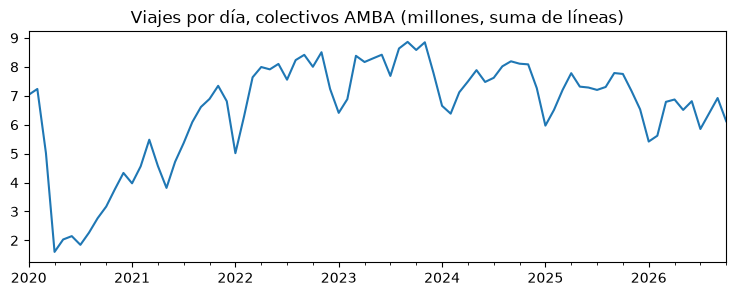

Meses por línea (mediana): 82.0 | líneas con panel completo: 311


In [2]:
tot = panel.groupby('mes').viajes_dia.sum() / 1e6
ax = tot.plot(figsize=(9, 3), title='Viajes por día, colectivos AMBA (millones, suma de líneas)')
ax.set_xlabel(''); plt.show()
print('Meses por línea (mediana):', lineas.meses.median(), '| líneas con panel completo:', (lineas.meses >= 80).sum())

## 2. Cruce con la geografía
El nombre de una línea no es igual en todas las fuentes, así que el cruce se hace en cascada y se registra cómo cruzó cada una (`match_geo`).

In [3]:
print(lineas.match_geo.value_counts(dropna=False))
con = lineas.largo_km.notna()
print(f'Viajes cubiertos por geografía: {lineas[con].viajes_dia_med.sum() / lineas.viajes_dia_med.sum():.1%}')
lineas[~con].groupby('jurisdiccion').agg(lineas=('linea_key', 'size'), viajes_dia_med_total=('viajes_dia_med', 'sum')).round(0)

match_geo
exacto            277
NaN                70
base               54
caba->nacional     31
Name: count, dtype: int64
Viajes cubiertos por geografía: 92.7%


,lineas,viajes_dia_med_total
jurisdiccion,,
MUNICIPAL,48,285710.0
NACIONAL,5,86676.0
PROVINCIAL,17,195726.0


## 3. Grupos de líneas comparables
KMeans dentro de cada jurisdicción, con tres rasgos: **largo**, **distancia al centro** y **escala de demanda** (en logaritmos).
Idea intuitiva: agrupar líneas "del mismo tipo" para después preguntar si una se comporta distinto que las de su grupo.

*Supuestos:* el largo viene del shapefile (promedio de ramales); las paradas son **aproximadas** (largo ÷ 350 m, no hay datos de paradas);
la distancia al centro usa el Obelisco como referencia.

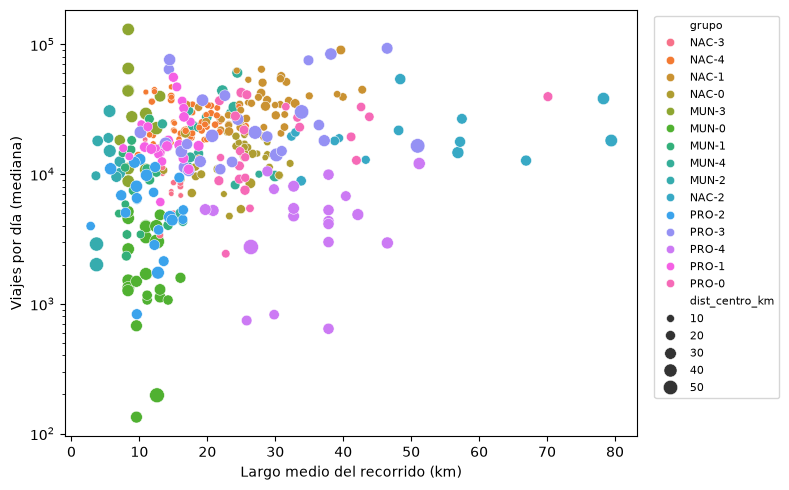

In [4]:
d = lineas.dropna(subset=['grupo'])
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=d, x='largo_km', y='viajes_dia_med', hue='grupo', size='dist_centro_km', sizes=(15, 120), ax=ax)
ax.set_yscale('log'); ax.set_xlabel('Largo medio del recorrido (km)'); ax.set_ylabel('Viajes por día (mediana)')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8); plt.tight_layout()
plt.savefig('../outputs/figures/grupos_comparables.png', dpi=150); plt.show()

In [5]:
d.groupby('grupo').agg(lineas=('linea_key','size'), largo_km=('largo_km','median'), dist_centro_km=('dist_centro_km','median'),
                       viajes_dia=('viajes_dia_med','median')).round(1)

,lineas,largo_km,dist_centro_km,viajes_dia
grupo,,,,
MUN-0,24,11.0,33.9,1504.9
MUN-1,16,9.0,17.9,8538.2
MUN-2,10,5.5,27.4,11313.5
MUN-3,13,8.4,34.9,27695.8
MUN-4,19,18.7,23.1,16447.7
NAC-0,36,25.2,8.8,13416.8
NAC-1,45,27.9,10.1,34056.4
NAC-2,14,48.3,23.0,18536.3
NAC-3,13,14.7,2.5,8013.6


## 4. Ejemplo: una línea frente a su grupo
Esta es la comparación que usarán los métodos de la Fase 3: la serie de una línea (normalizada a 100 en 2023) contra la mediana de sus pares.

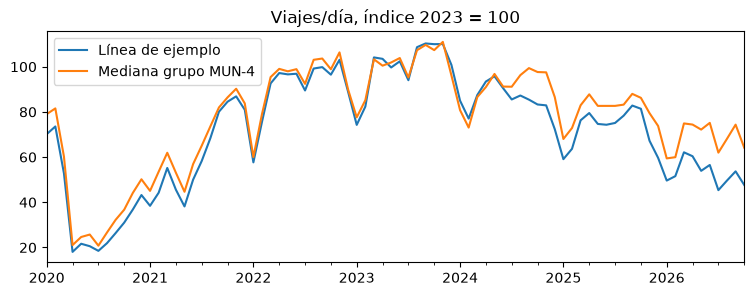

In [6]:
ej = d.sort_values('viajes_dia_med').iloc[len(d)//2]
g = panel[(panel.dias >= 25) & (panel.grupo == ej.grupo)].copy()
g['idx'] = g.groupby(['jurisdiccion','linea_key']).viajes_dia.transform(lambda s: 100 * s / s[g.loc[s.index,'mes'].dt.year == 2023].mean())
pares = g[g.linea_key != ej.linea_key].groupby('mes').idx.median()
propia = g[(g.linea_key == ej.linea_key) & (g.jurisdiccion == ej.jurisdiccion)].groupby('mes').idx.mean()
ax = propia.plot(figsize=(9, 3), label='Línea de ejemplo'); pares.plot(ax=ax, label=f'Mediana grupo {ej.grupo}')
ax.legend(); ax.set_xlabel(''); ax.set_title('Viajes/día, índice 2023 = 100'); plt.show()

## Qué sigue
- **Fase 2:** simular, sobre estas líneas reales, la distribución de viajes por sección y plantar un fraude simulado en un subconjunto.
- Pendiente: la matriz OD de GCBA (fuente 5) para calibrar distancias de viaje; se verifica al empezar la Fase 2.